# 02 — The baseline, step by step

**Goal of this notebook:** set out exactly what `train.py` does, one step at a time, using the
**plain baseline**: no feature engineering, every text column one-hot encoded, blanks filled with
the median or the most common answer.

This notebook is the **"before" picture**. Notebook 03 compares every feature idea against the
numbers produced here.

**Why this notebook does not import `common.py`:** `common.py` changes as features are added.
This notebook stays frozen on the plain baseline, so "before" never moves.

The steps, in the same order as `train.py`:

1. Split the data 60 / 20 / 20
2. Preprocess (impute, one-hot, standardize)
3. Pick the regularization strength `C` on validation
4. Train the same model three ways: scikit-learn, a manual PyTorch loop, PyTorch `nn.Module`
5. Check that the three agree
6. Pick the decision threshold from business costs, on validation
7. Report final numbers on the test set, against two naive baselines


## 0. Setup

The settings below mirror the top of `train.py`. They are duplicated rather than imported so this
notebook stays pinned to the plain baseline; if a setting changes in `train.py`, it has to be
changed here too.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, log_loss

TARGET = "HadHeartAttack"
SEED = 42

# --- settings copied from train.py ---
COST_FN = 2436.0    # cost of missing a real heart attack
COST_FP = 300.0     # cost of a false alarm (8.1x cheaper; only the RATIO moves the threshold)
C_GRID = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0]
LR = 0.5            # learning rate for both PyTorch versions
EPOCHS = 3000
DTYPE = torch.float64

torch.manual_seed(SEED)
np.random.seed(SEED)

URL = "https://raw.githubusercontent.com/Wilrick1234/daiist-assignment-1/main/data/heart_2022_sample.csv"
if os.path.exists("data/heart_2022_sample.csv"):
    raw = pd.read_csv("data/heart_2022_sample.csv")      # running inside the repo
else:
    raw = pd.read_csv(URL)                                # running in Colab

raw = raw.dropna(subset=[TARGET])
print(f"Loaded {len(raw):,} rows")

Loaded 20,000 rows


## 1. Split: 60% train / 20% validation / 20% test

| Part | Its job |
|---|---|
| **Train** (60%) | The model learns its coefficients here |
| **Validation** (20%) | We choose settings here: `C` and the decision threshold |
| **Test** (20%) | Used **once**, at the very end, for honest final numbers |

`stratify=` keeps the 5.7% heart attack rate the same in all three parts. Without it, one part
could get noticeably more heart attacks than another by luck.

**Why a random split and not a time-based one?** Not because this is classification
(fraud or churn models are classification and *do* need time splits). It's because this survey
is one snapshot from 2022 with no dates, and every row is a different person. There's no
"future" that could leak into training.

In [2]:
# Exactly the same two calls as load_and_split() in train.py
train_val, test = train_test_split(raw, test_size=0.20, stratify=raw[TARGET], random_state=SEED)
train, val = train_test_split(train_val, test_size=0.25, stratify=train_val[TARGET], random_state=SEED)
# 0.25 of the remaining 80% = 20% of all rows


def split_x_y(data):
    """Features = every column except the target. Target = 1 if 'Yes', else 0."""
    X = data.drop(columns=[TARGET])
    y = (data[TARGET] == "Yes").astype(int).to_numpy()
    return X, y


X_train_df, y_train = split_x_y(train)
X_val_df, y_val = split_x_y(val)
X_test_df, y_test = split_x_y(test)

for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:5s} {len(y):6,} rows   {y.sum():4d} heart attacks   rate {y.mean():.2%}")

train 12,000 rows    682 heart attacks   rate 5.68%
val    4,000 rows    227 heart attacks   rate 5.67%
test   4,000 rows    227 heart attacks   rate 5.67%


## 2. Preprocessing

Three things happen, in this order:

1. **Impute:** fill blanks. Numbers get the median, text gets the most common answer.
2. **One-hot encode:** a model can't multiply the word "Excellent", so each text column becomes
   several 0/1 columns, one per category. `drop="first"` leaves one category out (it becomes the
   reference the intercept absorbs); otherwise the columns plus the intercept would be perfectly
   collinear.
3. **Standardize:** rescale every column to mean 0, standard deviation 1. Gradient descent
   struggles when one column ranges 0 to 300 and another 0 to 1. Standardizing is what lets the
   PyTorch loops reach the same answer as scikit-learn.

**Critical:** we `fit` on the training rows only, then `transform` all three parts. Fitting on
everything would let validation and test information leak into training.

In [3]:
numeric_columns = [c for c in X_train_df.columns if pd.api.types.is_numeric_dtype(X_train_df[c])]
text_columns = [c for c in X_train_df.columns if c not in numeric_columns]

text_steps = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
])
encode = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_columns),
    ("cat", text_steps, text_columns),
], verbose_feature_names_out=False)
preprocessor = Pipeline([("encode", encode), ("scale", StandardScaler())])

X_train = preprocessor.fit_transform(X_train_df)     # learn medians, categories, means: TRAIN ONLY
X_val = preprocessor.transform(X_val_df)              # then just apply them
X_test = preprocessor.transform(X_test_df)

feature_names = list(preprocessor.named_steps["encode"].get_feature_names_out())
print(f"Before: {X_train_df.shape[1]} columns ({len(numeric_columns)} numeric + {len(text_columns)} text)")
print(f"After:  {X_train.shape[1]} columns (one-hot expanded the text ones)")

Before: 39 columns (6 numeric + 33 text)
After:  121 columns (one-hot expanded the text ones)


In [4]:
# See the expansion: what did GeneralHealth turn into?
print([f for f in feature_names if f.startswith("GeneralHealth")])
print("'Excellent' is missing on purpose: that's drop='first'. It's the reference category.")

['GeneralHealth_Fair', 'GeneralHealth_Good', 'GeneralHealth_Poor', 'GeneralHealth_Very good']
'Excellent' is missing on purpose: that's drop='first'. It's the reference category.


**What I see:** 39 raw columns (6 numeric + 33 text) become **121** model columns. GeneralHealth
alone becomes 4 columns, AgeCategory 12, State 53. That's 121 coefficients to estimate from 682
heart attacks in the training rows. Many of the feature ideas in notebook 03 are about getting
the same information into **fewer** columns.

## 3. Choose the regularization strength `C` (on validation)

`C` controls how much the model is punished for large coefficients.
**Smaller C = stronger penalty = simpler model.** It's the one setting worth tuning. We try each
value in `C_GRID`, score each on **validation** PR-AUC, and keep the best, exactly like `train.py`.

In [5]:
sweep = {}
for C in C_GRID:
    model = LogisticRegression(C=C, max_iter=10_000, tol=1e-10)
    model.fit(X_train, y_train)
    p_val = model.predict_proba(X_val)[:, 1]
    sweep[C] = average_precision_score(y_val, p_val)
    print(f"C = {C:<8} validation PR-AUC = {sweep[C]:.4f}")

C = max(sweep, key=sweep.get)
print(f"\nChosen C = {C}")

C = 0.0001   validation PR-AUC = 0.3969
C = 0.001    validation PR-AUC = 0.4315
C = 0.01     validation PR-AUC = 0.4211


C = 0.1      validation PR-AUC = 0.4109
C = 1.0      validation PR-AUC = 0.4081
C = 10.0     validation PR-AUC = 0.4082

Chosen C = 0.001


**What I see:** **C = 0.001** wins, with validation PR-AUC 0.4315. C = 0.0001 is too strong — the
model is squeezed too hard and scores 0.3969 — while C = 0.01 and above are weaker and nearly
identical to each other. This is the same C that `main.py train` picks.

The earlier exploratory work in `explore.ipynb` used C = 0.01, which scores 0.4211. `train.py`
searches a wider grid and settles on 0.001, so the baseline to beat throughout notebook 03 is
**0.4315**.


## 4. Model 1 of 3: scikit-learn

The one-liner. Everything below is what this line does on the inside.

In [6]:
sk = LogisticRegression(C=C, max_iter=10_000, tol=1e-10)
sk.fit(X_train, y_train)
print(f"Learned {len(sk.coef_[0])} coefficients + 1 intercept")

Learned 121 coefficients + 1 intercept


## 5. Model 2 of 3: the manual PyTorch loop

The model is `probability = sigmoid(X @ w + b)`. All weights start at zero, then 3,000 times:

1. **Forward:** compute predictions with the current weights.
2. **Loss:** binary cross-entropy plus the regularization penalty.
3. **Backward:** `loss.backward()` computes the gradient, the direction that makes the loss
   *bigger*.
4. **Update:** step the weights in the *opposite* direction.

**The conversion that makes the three agree.** scikit-learn minimizes
`0.5 × ||w||² + C × Σ(errors)`, while this loop minimizes `mean(errors) + (λ/2) × ||w||²`.
Dividing scikit-learn's objective by `C × n` makes the two identical when **λ = 1 / (C × n)**.
If this conversion is wrong, the three implementations optimize different objectives and cannot
agree no matter how long they run.


In [7]:
Xt = torch.tensor(X_train, dtype=DTYPE)
yt = torch.tensor(y_train, dtype=DTYPE)
n, d = Xt.shape
lam = 1.0 / (C * n)                       # <- the conversion
print(f"n = {n}, d = {d}, lambda = {lam:.2e}")

w = torch.zeros(d, dtype=DTYPE, requires_grad=True)
b = torch.zeros(1, dtype=DTYPE, requires_grad=True)
history_manual = []

for epoch in range(EPOCHS):
    z = Xt @ w + b                                          # 1. forward: log-odds
    p = 1 / (1 + torch.exp(-z))                             #    sigmoid -> probability
    p = p.clamp(1e-12, 1 - 1e-12)                           #    avoid log(0)
    bce = -(yt * torch.log(p) + (1 - yt) * torch.log(1 - p)).mean()
    loss = bce + 0.5 * lam * (w ** 2).sum()                 # 2. loss + penalty

    loss.backward()                                         # 3. backward: fills w.grad, b.grad
    with torch.no_grad():                                   # 4. update (not tracked)
        w -= LR * w.grad
        b -= LR * b.grad
    w.grad.zero_()                                          #    reset, or gradients add up
    b.grad.zero_()

    history_manual.append(loss.item())
    if epoch % 500 == 0:
        print(f"epoch {epoch:5d}   loss {loss.item():.6f}")

print(f"epoch {EPOCHS:5d}   loss {history_manual[-1]:.6f}")

n = 12000, d = 121, lambda = 8.33e-02


epoch     0   loss 0.693147


epoch   500   loss 0.169789


epoch  1000   loss 0.169789


epoch  1500   loss 0.169789


epoch  2000   loss 0.169789


epoch  2500   loss 0.169789


epoch  3000   loss 0.169789


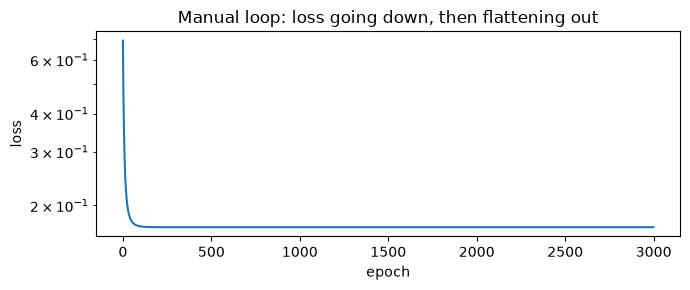

In [8]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(history_manual)
ax.set_yscale("log")
ax.set_xlabel("epoch")
ax.set_ylabel("loss")
ax.set_title("Manual loop: loss going down, then flattening out")
plt.tight_layout()
plt.show()

**What I see:** the loss drops from 0.693 — that is log 2, the value when every prediction is
0.5 — to 0.1698 within about 200 epochs, then stays flat. The remaining 2,800 epochs change
nothing visible. With C = 0.001 the penalty is strong (λ = 0.083), which makes the problem
well-conditioned and easy for gradient descent.


## 6. Model 3 of 3: standard PyTorch (`nn.Module` + `optim`)

Same maths, the usual PyTorch way:

- `nn.Linear` holds `w` and `b` for us (the class below is the same as `LogisticRegressionNet`
  in `common.py`).
- `BCEWithLogitsLoss` = sigmoid + cross-entropy in one step (numerically safer).
- `optimizer.step()` does the update.

Two details make it match the manual loop exactly:

- We **set the starting weights to zero** (`nn.Linear` normally starts random).
- `weight_decay=lam` adds `lam × w` to the gradient, which is exactly the derivative of
  `(lam/2) × ||w||²`. We apply it to the **weights only, not the bias**, like scikit-learn.

In [9]:
class LogisticRegressionNet(nn.Module):
    """One linear layer. forward() returns log-odds; the sigmoid is applied later."""
    def __init__(self, n_features):
        super().__init__()
        self.linear = nn.Linear(n_features, 1)

    def forward(self, x):
        return self.linear(x).squeeze(1)


module = LogisticRegressionNet(d).to(DTYPE)
nn.init.zeros_(module.linear.weight)
nn.init.zeros_(module.linear.bias)

optimizer = torch.optim.SGD([
    {"params": [module.linear.weight], "weight_decay": lam},   # penalize the weights
    {"params": [module.linear.bias], "weight_decay": 0.0},     # but not the bias
], lr=LR)
loss_fn = nn.BCEWithLogitsLoss()
history_module = []

for epoch in range(EPOCHS):
    optimizer.zero_grad()
    loss = loss_fn(module(Xt), yt)
    loss.backward()
    optimizer.step()
    penalty = 0.5 * lam * (module.linear.weight ** 2).sum().item()
    history_module.append(loss.item() + penalty)               # same objective as the manual loop

print(f"final loss {history_module[-1]:.6f}")

final loss 0.169789


## 7. Do the three agree?

We compare two things on the test rows: the predicted probabilities and the learned
coefficients. "Biggest difference" means the largest gap over all 4,000 people (or all
coefficients).

In [10]:
def predict_manual(X):
    return 1 / (1 + np.exp(-(X @ w.detach().numpy() + b.detach().numpy())))


def predict_module(X):
    with torch.no_grad():
        return torch.sigmoid(module(torch.tensor(X, dtype=DTYPE))).numpy()


p_sk = sk.predict_proba(X_test)[:, 1]
p_manual = predict_manual(X_test)
p_module = predict_module(X_test)

coef_sk = sk.coef_[0]
coef_manual = w.detach().numpy()
coef_module = module.linear.weight.detach().numpy()[0]

print("Biggest difference in predicted probability (test set):")
print(f"  sklearn vs manual   : {np.abs(p_sk - p_manual).max():.2e}")
print(f"  sklearn vs nn.Module: {np.abs(p_sk - p_module).max():.2e}")
print(f"  manual vs nn.Module : {np.abs(p_manual - p_module).max():.2e}")
print("\nBiggest difference in coefficients:")
print(f"  sklearn vs manual   : {np.abs(coef_sk - coef_manual).max():.2e}")
print(f"  manual vs nn.Module : {np.abs(coef_manual - coef_module).max():.2e}")


def objective(p, y, coefs):
    """The shared objective: mean cross-entropy + (lam/2)*||w||^2, on the training rows."""
    return log_loss(y, np.clip(p, 1e-12, 1 - 1e-12)) + 0.5 * lam * np.sum(coefs ** 2)


print("\nFinal training objective (lower = better):")
print(f"  sklearn  : {objective(sk.predict_proba(X_train)[:, 1], y_train, coef_sk):.10f}")
print(f"  manual   : {objective(predict_manual(X_train), y_train, coef_manual):.10f}")
print(f"  nn.Module: {objective(predict_module(X_train), y_train, coef_module):.10f}")

Biggest difference in predicted probability (test set):
  sklearn vs manual   : 8.80e-08
  sklearn vs nn.Module: 8.80e-08
  manual vs nn.Module : 2.78e-16

Biggest difference in coefficients:
  sklearn vs manual   : 6.56e-08
  manual vs nn.Module : 2.08e-17

Final training objective (lower = better):
  sklearn  : 0.1697894815
  manual   : 0.1697894815
  nn.Module: 0.1697894815


**What I see:**

- **Manual loop vs nn.Module:** differences of about **1e-16**. That's the limit of computer
  arithmetic: they run the same operations in the same order, so they're the same model.
- **scikit-learn vs PyTorch:** differences of about **1e-7** in probabilities and coefficients.
  Still tiny. The small gap is scikit-learn's own stopping rule (it stops when improvements get
  below its tolerance), not a different answer.
- **Training objective:** identical to 10 decimal places for all three. All three reached the same
  bottom of the same objective. That's the point of the assignment: three very different-looking
  pieces of code, one model.

### Break it on purpose

Agreement happens *because* gradient descent ran long enough to reach the bottom. Run the manual
loop with too few epochs and watch the gap to scikit-learn grow.

In [11]:
def run_manual_loop(epochs, lr):
    """The same manual loop as above, returned as numpy weights."""
    w2 = torch.zeros(d, dtype=DTYPE, requires_grad=True)
    b2 = torch.zeros(1, dtype=DTYPE, requires_grad=True)
    for _ in range(epochs):
        p = (1 / (1 + torch.exp(-(Xt @ w2 + b2)))).clamp(1e-12, 1 - 1e-12)
        loss = -(yt * torch.log(p) + (1 - yt) * torch.log(1 - p)).mean() + 0.5 * lam * (w2 ** 2).sum()
        loss.backward()
        with torch.no_grad():
            w2 -= lr * w2.grad
            b2 -= lr * b2.grad
        w2.grad.zero_()
        b2.grad.zero_()
    return w2.detach().numpy()


for epochs in [10, 50, 200, 1000, 3000]:
    gap = np.abs(coef_sk - run_manual_loop(epochs, LR)).max()
    print(f"{epochs:5d} epochs, lr={LR}  -> biggest coefficient gap vs sklearn: {gap:.2e}")

gap = np.abs(coef_sk - run_manual_loop(3000, 0.01)).max()
print(f" 3000 epochs, lr=0.01 -> biggest coefficient gap vs sklearn: {gap:.2e}")

   10 epochs, lr=0.5  -> biggest coefficient gap vs sklearn: 1.56e-01
   50 epochs, lr=0.5  -> biggest coefficient gap vs sklearn: 4.33e-02
  200 epochs, lr=0.5  -> biggest coefficient gap vs sklearn: 2.85e-03


 1000 epochs, lr=0.5  -> biggest coefficient gap vs sklearn: 6.29e-08


 3000 epochs, lr=0.5  -> biggest coefficient gap vs sklearn: 6.56e-08


 3000 epochs, lr=0.01 -> biggest coefficient gap vs sklearn: 3.58e-02


**What I see:** with 10 epochs the biggest coefficient is off by 0.16; with 50 by 0.04; with 200
by 0.003; from 1,000 epochs on it matches scikit-learn to 1e-7. At a learning rate of 0.01, even
3,000 epochs leave a gap of 0.036, about the same as 50 epochs at 0.5. What matters is roughly
*learning rate × epochs*: smaller steps need more of them.

This is the evidence behind the claim that the three implementations agree **because gradient
descent converged**, rather than by coincidence — and it shows exactly what non-convergence would
have looked like.


## 8. The decision threshold

The model outputs a probability. Acting on it requires a cutoff: flag everyone above it. Where
that cutoff goes is a **business decision**, set by two numbers:

- `COST_FN`: the cost of missing a real heart attack (false negative)
- `COST_FP`: the cost of a false alarm (false positive)

For every threshold from 0.01 to 0.99 the total cost is computed on **validation** and the
cheapest is kept, exactly as `train.py` does. Choosing it on the test set would mean reporting a
number that had been tuned to that same data.


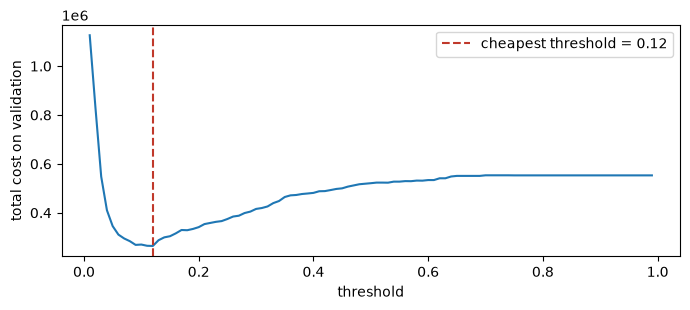

Theory: for a well-calibrated model the best threshold is COST_FP/(COST_FP+COST_FN) = 0.110
We found 0.12 on validation.


In [12]:
def business_cost(y, flagged):
    missed = ((flagged == 0) & (y == 1)).sum()
    false_alarms = ((flagged == 1) & (y == 0)).sum()
    return COST_FN * missed + COST_FP * false_alarms


p_val_sk = sk.predict_proba(X_val)[:, 1]
thresholds = np.round(np.arange(0.01, 1.00, 0.01), 2)
costs = [business_cost(y_val, (p_val_sk >= t).astype(int)) for t in thresholds]
best_t = thresholds[int(np.argmin(costs))]

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(thresholds, costs)
ax.axvline(best_t, color="#c0392b", linestyle="--", label=f"cheapest threshold = {best_t:.2f}")
ax.set_xlabel("threshold")
ax.set_ylabel("total cost on validation")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Theory: for a well-calibrated model the best threshold is COST_FP/(COST_FP+COST_FN) = "
      f"{COST_FP / (COST_FP + COST_FN):.3f}")
print(f"We found {best_t:.2f} on validation.")

**What I see:** the cheapest threshold on validation is **0.12**, and theory gives
300 / (300 + 2,436) = 0.110 for a well-calibrated model. They land one grid step apart, which
says the model's probabilities can roughly be taken at face value. The grid moves in steps of
0.01 and the cost curve is nearly flat near its minimum, so a one-step gap is not evidence of
miscalibration.

The cost curve drops steeply up to 0.12, then rises slowly. Past about 0.7 it is flat at 552,972:
nobody is flagged any more, so every one of the 227 heart attacks is missed (227 × $2,436).

**Where the costs come from:** `COST_FN = 2,436` and `COST_FP = 300` are the business framing's
numbers, making a missed case 8.1 times as expensive as an unnecessary check-up. Only the
**ratio** moves the threshold; the absolute dollars scale the cost column, which is why it reads
as money. At the template's 10:1 ratio the threshold would sit at 0.09 instead.


## 9. Final numbers on the test set

Now, and only now, we touch the test set. We compare our model against the two naive baselines
`train.py` uses:

- **Flag nobody:** never raises an alarm, misses every heart attack.
- **Flag everyone:** catches every heart attack, alarms on every healthy person.

In [13]:
def summarize(name, flagged, p=None):
    caught = int(((flagged == 1) & (y_test == 1)).sum())
    missed = int(((flagged == 0) & (y_test == 1)).sum())
    false_alarms = int(((flagged == 1) & (y_test == 0)).sum())
    row = {"strategy": name, "caught": caught, "missed": missed, "false_alarms": false_alarms,
           "recall": caught / (caught + missed),
           "precision": caught / (caught + false_alarms) if caught + false_alarms > 0 else 0.0,
           "cost_per_1000": 1000 * business_cost(y_test, flagged) / len(y_test)}
    if p is not None:
        row["pr_auc"] = average_precision_score(y_test, p)
        row["roc_auc"] = roc_auc_score(y_test, p)
    return row


results = pd.DataFrame([
    summarize("flag nobody", np.zeros(len(y_test), dtype=int)),
    summarize("flag everyone", np.ones(len(y_test), dtype=int)),
    summarize(f"our model (threshold {best_t:.2f})", (p_sk >= best_t).astype(int), p_sk),
])
print(f"Random guessing would give PR-AUC ≈ {y_test.mean():.4f} (the heart attack rate)")
results.round(4)

Random guessing would give PR-AUC ≈ 0.0568 (the heart attack rate)


,strategy,caught,missed,false_alarms,recall,precision,cost_per_1000,pr_auc,roc_auc
0,flag nobody,0,227,0,0.000,0.0000,138243.0,NaN,NaN
1,flag everyone,227,0,3773,1.000,0.0568,282975.0,NaN,NaN
2,our model (threshold 0.12),116,111,225,0.511,0.3402,84474.0,0.3739,0.8674


**What I see:**

- At threshold 0.12 the model **catches 116 of 227** heart attacks (recall 51.1%) with 225 false
  alarms (precision 34.0%: about 1 in 3 flagged people really had one).
- **Cost per 1,000 people: \$84,474**, vs \$138,243 for "flag nobody" and \$282,975 for "flag
  everyone". The model cuts the cost of doing nothing by 39%.
- **Test PR-AUC = 0.3739**, vs 0.0568 for random guessing (6.6 times better). ROC-AUC = 0.8674.
- Test PR-AUC (0.3739) is lower than validation (0.4315). That's normal: C was *chosen* on
  validation, so validation is slightly flattering, and with only 227 positives either number can
  move a few hundredths by luck. This is why the test set is only used once.
- **Recall is a consequence of the costs, not a target.** At the template's 10:1 ratio the
  threshold was 0.09 and recall 61.7%; at the true 8.1:1 ratio a false alarm is relatively more
  expensive, the bar rises to 0.12, and recall falls to 51.1% while precision climbs from 27.8%
  to 34.0%. Nothing about the fitted model changed — only the cutoff did.


## 10. Which features mattered?

Because everything was standardized, coefficients are comparable: each one is the change in
log-odds for a **one standard deviation** change in that feature. Red raises the risk, blue
lowers it.

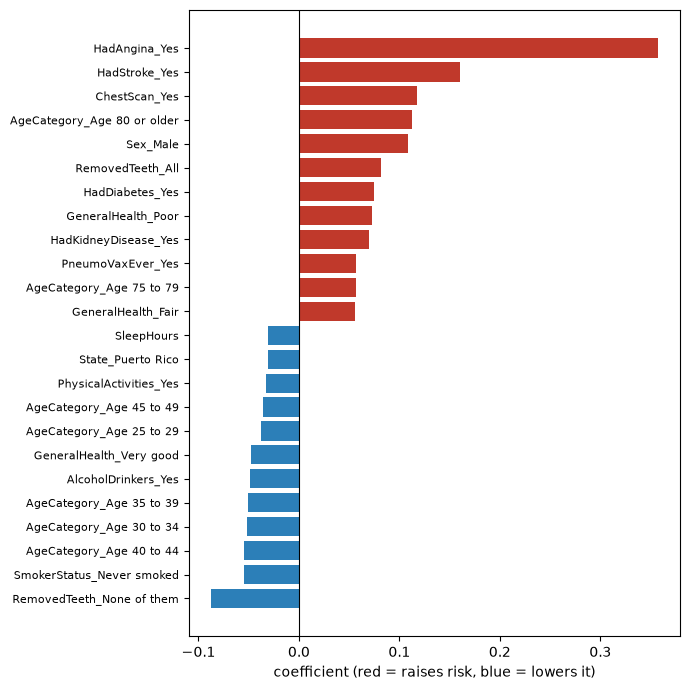

In [14]:
coefs = pd.Series(coef_sk, index=feature_names).sort_values()
top = pd.concat([coefs.head(12), coefs.tail(12)])

fig, ax = plt.subplots(figsize=(7, 7))
colors = ["#2c7fb8" if v < 0 else "#c0392b" for v in top.values]
ax.barh(top.index, top.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("coefficient (red = raises risk, blue = lowers it)")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

**What I see:**

- **HadAngina_Yes** is by far the biggest coefficient (about 0.36), more than twice the next one
  (HadStroke_Yes, about 0.16). **ChestScan_Yes** is third. The two leakage suspects from notebook
  01 are carrying a lot of the model.
- Then come Age 80+, Sex_Male, RemovedTeeth_All, HadDiabetes_Yes and GeneralHealth_Poor.
- On the blue side, RemovedTeeth_None and SmokerStatus_Never smoked lower the risk, as the EDA
  suggested.
- Age is spread over **12 separate columns**, and some young age groups get negative coefficients.
  That makes the age effect hard to read, and it's one more argument for turning age into a
  single number (notebook 03).
- **SleepHours** gets one small negative coefficient, but the EDA showed sleep is U-shaped. A
  single straight-line coefficient can't describe a U.

## Baseline ("before") numbers

| What | Value |
|---|---|
| Features after encoding | 121 |
| Chosen C | 0.001 |
| **Validation PR-AUC** (what notebook 03 compares against) | **0.4315** |
| Test PR-AUC / ROC-AUC | 0.3739 / 0.8674 |
| Threshold (COST_FN = 2,436, COST_FP = 300) | 0.12 |
| Test: caught / missed / false alarms | 116 / 111 / 225 |
| Cost per 1,000 people (model vs flag nobody vs flag everyone) | \$84,474 vs \$138,243 vs \$282,975 |
| Max probability gap sklearn vs manual vs nn.Module | about 1e-7 / 1e-16 |

**Next:** notebook 03 tests every feature idea and compares its validation PR-AUC against
**0.4315**. The test set stays untouched until `main.py train` runs the final version.
